<small>

### Library & Constant Values

</small>

In [5]:
from torchvision import datasets, transforms as T
import torch
import random
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision.models import regnet_y_400mf, RegNet_X_400MF_Weights
import torch.nn as nn
import time

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TRAIN_DIR = "../dataset/imagenette2-160/train"
VAL_DIR = "../dataset/imagenette2-160/val"
CLASS_NUM = 10
EPOCH = 50

<small>

### Data Acquisition & Data Preparation

</small>

In [7]:
train_transform = T.Compose([
    T.Resize(160),
    T.RandomCrop(160, padding=4),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.1),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    # T.RandomErasing(p=0.75, scale=(0.02, 0.1), value=0),
])

val_transform = T.Compose([
    T.Resize(160),
    T.CenterCrop(160),
    T.ToTensor(),
    T.Normalize(MEAN, STD)
])

In [8]:
train_ds = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_ds = datasets.ImageFolder(VAL_DIR, transform=val_transform)

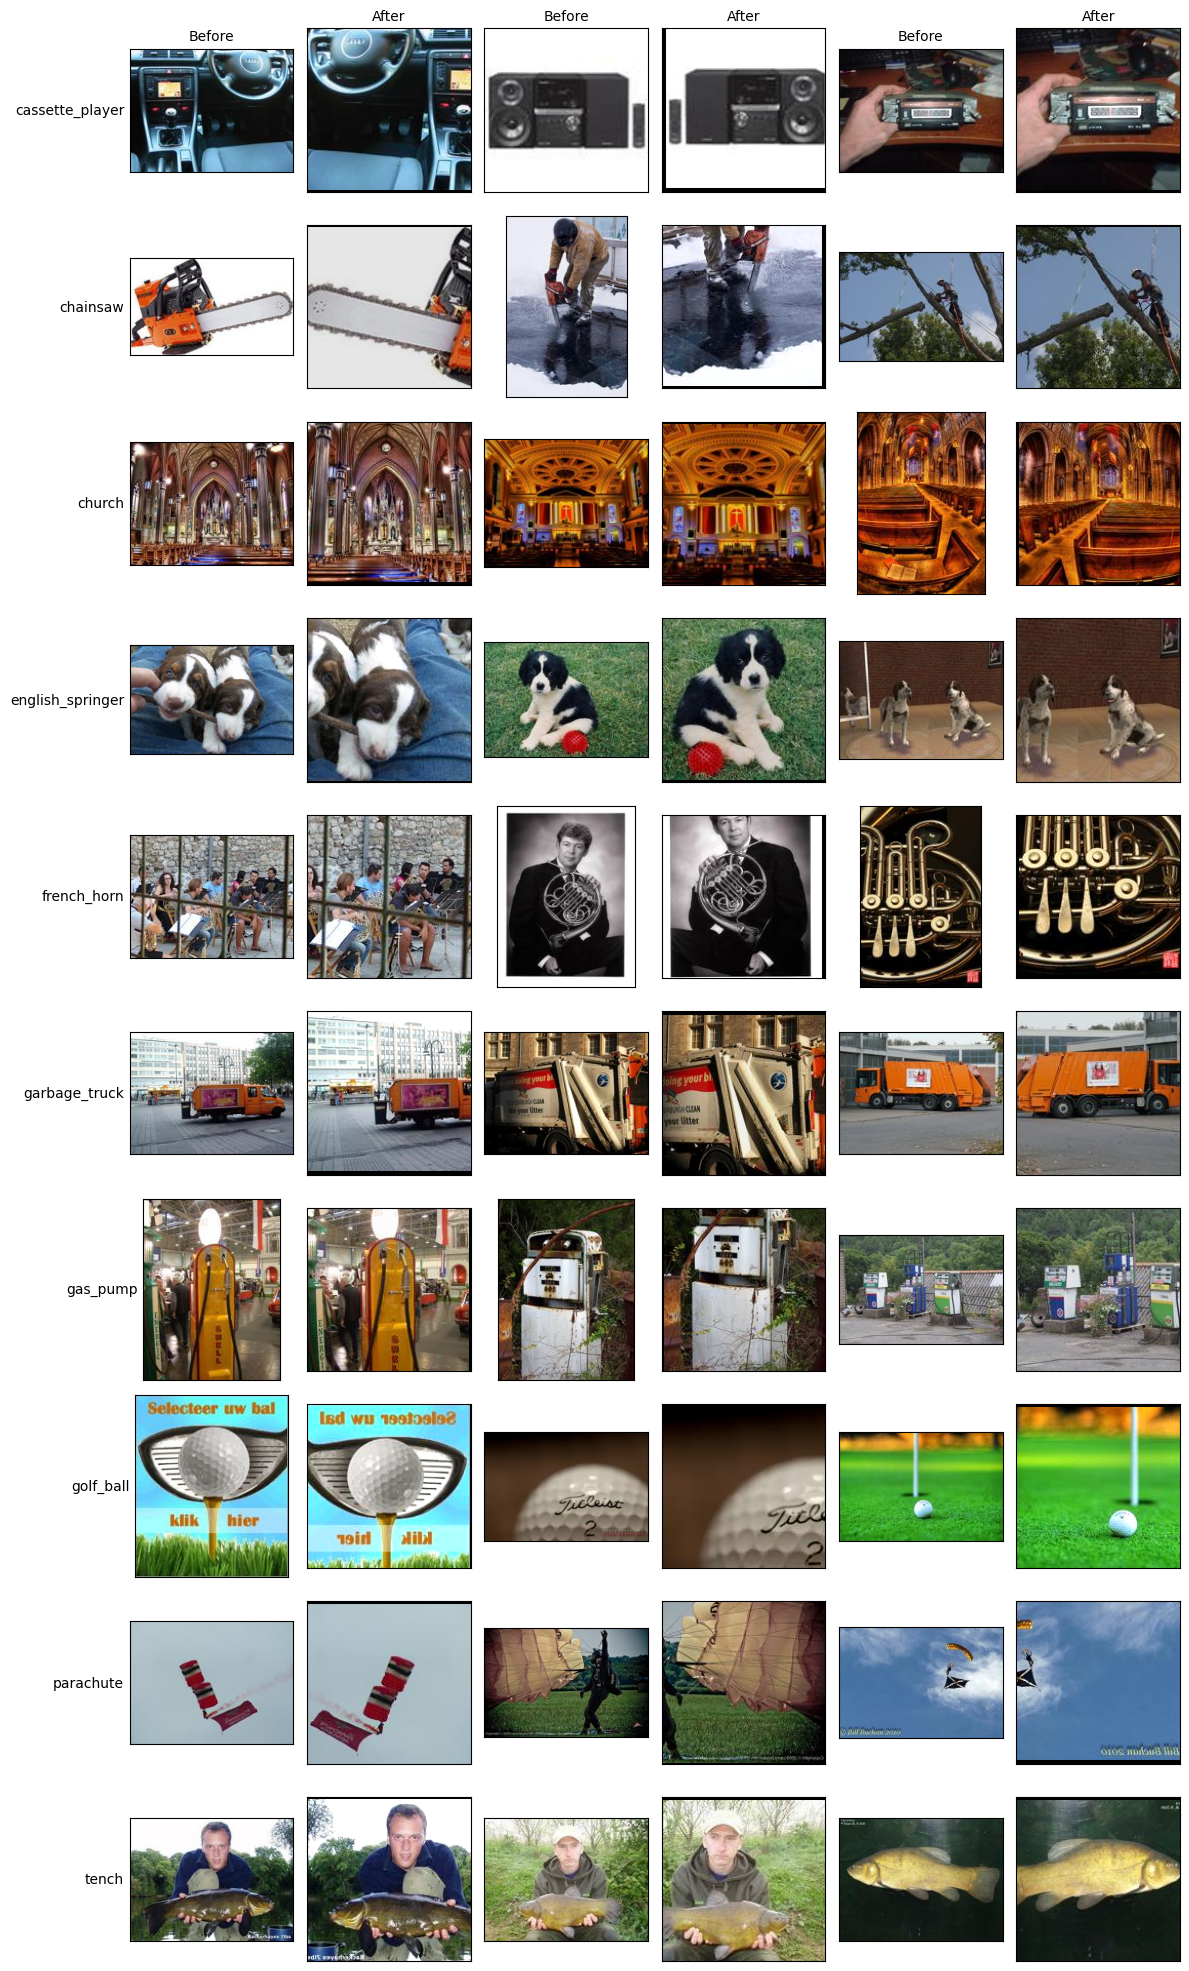

In [9]:
raw_train_ds = datasets.ImageFolder(TRAIN_DIR)

def denormalize(t):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

def plot_before_after(ds, tf, n_per_class=3, seed=0, save_path=None):
    rng = random.Random(seed)
    classes = ds.classes
    idx_by_class = {c: [] for c in range(len(classes))}
    for i, (_, label) in enumerate(ds.samples):
        idx_by_class[label].append(i)

    fig, axes = plt.subplots(len(classes), n_per_class * 2,
                             figsize=(2 * n_per_class * 2, 2 * len(classes)))
    for row, cls in enumerate(classes):
        for k, i in enumerate(rng.sample(idx_by_class[row], n_per_class)):
            img, _ = ds[i]
            axes[row, 2 * k].imshow(img)                          # before
            axes[row, 2 * k + 1].imshow(denormalize(tf(img)))     # after
            if row == 0:
                axes[row, 2 * k].set_title("Before", fontsize=10)
                axes[row, 2 * k + 1].set_title("After", fontsize=10)
        axes[row, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=10)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
    return fig

plot_before_after(raw_train_ds, train_transform, save_path="before_after.png")
plt.show()

In [10]:
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=4, pin_memory=True)

<small>

### Modelling and Traning (Baseline)

</small>

In [11]:
device = "cuda"
model = regnet_y_400mf(weights=None)
model.fc = nn.Linear(model.fc.in_features, CLASS_NUM)
model = model.to(device=device)

In [12]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-5, nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer=optimizer, max_lr=0.1, epochs=EPOCH, steps_per_epoch=len(train_dl))
scaler = torch.amp.GradScaler()

In [13]:
def train_one_epoch(model, loader):
    model.train()                                   # training mode (BatchNorm updates, etc.)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:                             # x: images [64,3,160,160], y: labels [64]
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)       # clear gradients from the previous batch
        with torch.autocast("cuda"):                # mixed precision: faster, less memory
            out = model(x)                          # 1. forward pass -> [64,10] scores
            loss = criterion(out, y)                # 2. loss
        scaler.scale(loss).backward()               # 3. backward pass (gradients)
        scaler.step(optimizer)                      # 4. update the weights
        scaler.update()
        scheduler.step()                            # update the learning rate (once per batch)

        total_loss += loss.item() * x.size(0)       # loss.item() = loss as a plain number
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n              # average loss, accuracy


@torch.no_grad()                                    # no gradients needed for evaluation
def evaluate(model, loader):
    model.eval()                                    # eval mode (BatchNorm uses saved stats)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda"):
            out = model(x)
            loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n


In [14]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc = 0.0

for epoch in range(EPOCH):
    t0 = time.time()
    tl, ta = train_one_epoch(model, train_dl)
    vl, va = evaluate(model, val_dl)
    for key, value in zip(history, (tl, ta, vl, va)):
        history[key].append(value)

    if va > best_acc:                               # keep the best checkpoint
        best_acc = va
        torch.save(model.state_dict(), "best.pth")

    print(f"epoch {epoch+1}/{EPOCH} | train loss {tl:.3f} acc {ta:.3f} "
          f"| val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.1f}s")

/tmp/ipykernel_180968/3154612446.py:14: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                            # update the learning rate (once per batch)


epoch 1/50 | train loss 2.218 acc 0.210 | val loss 2.017 acc 0.348 | 11.3s
epoch 2/50 | train loss 1.864 acc 0.417 | val loss 1.746 acc 0.469 | 9.6s
epoch 3/50 | train loss 1.674 acc 0.511 | val loss 2.383 acc 0.484 | 9.6s
epoch 4/50 | train loss 1.542 acc 0.574 | val loss 1.456 acc 0.602 | 9.6s
epoch 5/50 | train loss 1.438 acc 0.618 | val loss 5.304 acc 0.448 | 9.6s
epoch 6/50 | train loss 1.363 acc 0.653 | val loss 1.447 acc 0.654 | 9.7s
epoch 7/50 | train loss 1.248 acc 0.696 | val loss 1.293 acc 0.707 | 9.7s
epoch 8/50 | train loss 1.192 acc 0.721 | val loss 1.288 acc 0.709 | 9.7s
epoch 9/50 | train loss 1.135 acc 0.743 | val loss 1.301 acc 0.659 | 9.6s
epoch 10/50 | train loss 1.093 acc 0.761 | val loss 1.226 acc 0.719 | 9.7s
epoch 11/50 | train loss 1.052 acc 0.778 | val loss 1.170 acc 0.733 | 9.7s
epoch 12/50 | train loss 1.018 acc 0.784 | val loss 1.099 acc 0.764 | 9.7s
epoch 13/50 | train loss 0.997 acc 0.798 | val loss 1.084 acc 0.754 | 9.7s
epoch 14/50 | train loss 0.992 ac

<small>

### Training Results (Loss & Accuracy)

</small>

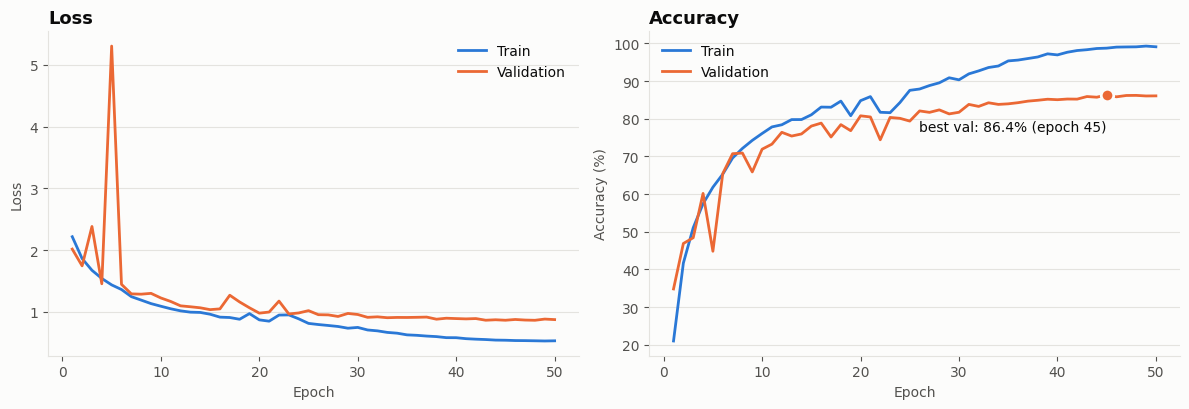

In [15]:
def plot_history(history, save_path=None):
    epochs = list(range(1, len(history["train_loss"]) + 1))
    train_c, val_c = "#2a78d6", "#eb6834"                 # blue = train, orange = validation
    surface, ink, muted, grid = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), facecolor=surface)
    panels = [
        (axes[0], "Loss", history["train_loss"], history["val_loss"], "Loss"),
        (axes[1], "Accuracy", [a * 100 for a in history["train_acc"]],
                              [a * 100 for a in history["val_acc"]], "Accuracy (%)"),
    ]
    for ax, title, train, val, ylabel in panels:
        ax.set_facecolor(surface)
        ax.plot(epochs, train, color=train_c, lw=2, label="Train")
        ax.plot(epochs, val, color=val_c, lw=2, label="Validation")
        ax.set_title(title, loc="left", fontsize=13, color=ink, fontweight="bold")
        ax.set_xlabel("Epoch", color=muted)
        ax.set_ylabel(ylabel, color=muted)
        ax.grid(axis="y", color=grid, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=muted)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(grid)
        ax.legend(frameon=False, labelcolor=ink, loc="best")

    # mark the best validation accuracy on the accuracy panel
    best = max(range(len(history["val_acc"])), key=history["val_acc"].__getitem__)
    best_acc = history["val_acc"][best] * 100
    axes[1].plot(best + 1, best_acc, "o", color=val_c, markersize=9,
                 markeredgecolor=surface, markeredgewidth=2, zorder=5)
    axes[1].annotate(f"best val: {best_acc:.1f}% (epoch {best + 1})",
                     xy=(best + 1, best_acc), xytext=(0, -26), textcoords="offset points",
                     ha="right", fontsize=10, color=ink)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight", facecolor=surface)
    return fig

plot_history(history, save_path="loss_accuracy.png")
plt.show()

<small>

### Modelling and Traning (Learning Rate Tuning)

</small>

In [16]:
device = "cuda"
model = regnet_y_400mf(weights=None)
model.fc = nn.Linear(model.fc.in_features, CLASS_NUM)
model = model.to(device=device)

In [17]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.03, momentum=0.9, weight_decay=5e-5, nesterov=True)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer=optimizer, max_lr=0.03, epochs=EPOCH, steps_per_epoch=len(train_dl))
scaler = torch.amp.GradScaler()

In [18]:
def train_one_epoch(model, loader):
    model.train()                                   # training mode (BatchNorm updates, etc.)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:                             # x: images [64,3,160,160], y: labels [64]
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)       # clear gradients from the previous batch
        with torch.autocast("cuda"):                # mixed precision: faster, less memory
            out = model(x)                          # 1. forward pass -> [64,10] scores
            loss = criterion(out, y)                # 2. loss
        scaler.scale(loss).backward()               # 3. backward pass (gradients)
        scaler.step(optimizer)                      # 4. update the weights
        scaler.update()
        scheduler.step()                            # update the learning rate (once per batch)

        total_loss += loss.item() * x.size(0)       # loss.item() = loss as a plain number
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n              # average loss, accuracy


@torch.no_grad()                                    # no gradients needed for evaluation
def evaluate(model, loader):
    model.eval()                                    # eval mode (BatchNorm uses saved stats)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda"):
            out = model(x)
            loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n


In [19]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc = 0.0

for epoch in range(EPOCH):
    t0 = time.time()
    tl, ta = train_one_epoch(model, train_dl)
    vl, va = evaluate(model, val_dl)
    for key, value in zip(history, (tl, ta, vl, va)):
        history[key].append(value)

    if va > best_acc:                               # keep the best checkpoint
        best_acc = va
        torch.save(model.state_dict(), "best.pth")

    print(f"epoch {epoch+1}/{EPOCH} | train loss {tl:.3f} acc {ta:.3f} "
          f"| val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.1f}s")

/tmp/ipykernel_180968/3154612446.py:14: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                            # update the learning rate (once per batch)


epoch 1/50 | train loss 2.284 acc 0.165 | val loss 2.452 acc 0.222 | 9.6s
epoch 2/50 | train loss 2.093 acc 0.284 | val loss 2.099 acc 0.369 | 9.6s
epoch 3/50 | train loss 1.888 acc 0.394 | val loss 2.006 acc 0.422 | 9.6s
epoch 4/50 | train loss 1.724 acc 0.482 | val loss 1.942 acc 0.479 | 9.6s
epoch 5/50 | train loss 1.579 acc 0.547 | val loss 1.577 acc 0.554 | 9.6s
epoch 6/50 | train loss 1.465 acc 0.604 | val loss 1.892 acc 0.587 | 9.6s
epoch 7/50 | train loss 1.371 acc 0.642 | val loss 1.443 acc 0.631 | 9.6s
epoch 8/50 | train loss 1.298 acc 0.671 | val loss 1.293 acc 0.682 | 9.6s
epoch 9/50 | train loss 1.247 acc 0.698 | val loss 1.346 acc 0.667 | 9.6s
epoch 10/50 | train loss 1.198 acc 0.715 | val loss 1.220 acc 0.715 | 9.7s
epoch 11/50 | train loss 1.150 acc 0.735 | val loss 1.253 acc 0.730 | 9.7s
epoch 12/50 | train loss 1.126 acc 0.745 | val loss 1.296 acc 0.685 | 9.6s
epoch 13/50 | train loss 1.081 acc 0.764 | val loss 1.149 acc 0.739 | 9.6s
epoch 14/50 | train loss 1.044 acc

<small>

### Training Results (Loss & Accuracy)

</small>

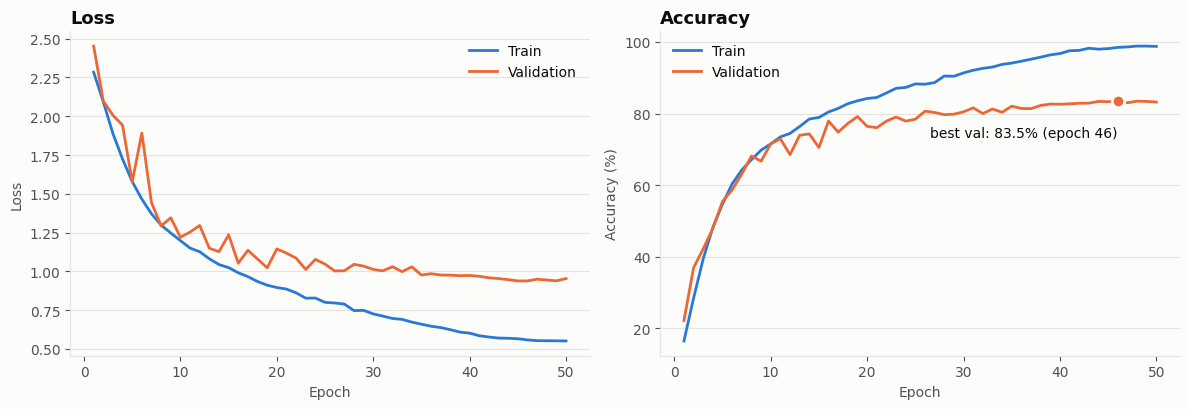

In [20]:
def plot_history(history, save_path=None):
    epochs = list(range(1, len(history["train_loss"]) + 1))
    train_c, val_c = "#2a78d6", "#eb6834"                 # blue = train, orange = validation
    surface, ink, muted, grid = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), facecolor=surface)
    panels = [
        (axes[0], "Loss", history["train_loss"], history["val_loss"], "Loss"),
        (axes[1], "Accuracy", [a * 100 for a in history["train_acc"]],
                              [a * 100 for a in history["val_acc"]], "Accuracy (%)"),
    ]
    for ax, title, train, val, ylabel in panels:
        ax.set_facecolor(surface)
        ax.plot(epochs, train, color=train_c, lw=2, label="Train")
        ax.plot(epochs, val, color=val_c, lw=2, label="Validation")
        ax.set_title(title, loc="left", fontsize=13, color=ink, fontweight="bold")
        ax.set_xlabel("Epoch", color=muted)
        ax.set_ylabel(ylabel, color=muted)
        ax.grid(axis="y", color=grid, lw=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=muted)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(grid)
        ax.legend(frameon=False, labelcolor=ink, loc="best")

    # mark the best validation accuracy on the accuracy panel
    best = max(range(len(history["val_acc"])), key=history["val_acc"].__getitem__)
    best_acc = history["val_acc"][best] * 100
    axes[1].plot(best + 1, best_acc, "o", color=val_c, markersize=9,
                 markeredgecolor=surface, markeredgewidth=2, zorder=5)
    axes[1].annotate(f"best val: {best_acc:.1f}% (epoch {best + 1})",
                     xy=(best + 1, best_acc), xytext=(0, -26), textcoords="offset points",
                     ha="right", fontsize=10, color=ink)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight", facecolor=surface)
    return fig

plot_history(history, save_path="loss_accuracy.png")
plt.show()